<a href="https://colab.research.google.com/github/luzcielponce-create/MS-E-226-Project-/blob/luzciel-correlations/streaming_data_correlation_coefficients.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5(b): Correlation of each covariate with Netflix (explore data only)


In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats #pearsonr gives r and a p-value

df = pd.read_csv("explore_80.csv")

# Turn any blank-looking strings (empty or just spaces) into real missing values (NA)
df = df.replace(r"^\s*$", pd.NA, regex=True)

# Outcome: 1 = on Netflix at the dataset snapshot, 0 = not on Netflix
y = pd.to_numeric(df["Netflix"], errors="coerce") #errors="coerce" turns anything non-numeric into NaN instead of crashing

# Print sample size and class balance so we can report them
print("Rows:", len(df))
print("Netflix = 1:", int((y == 1).sum()), " Netflix = 0:", int((y == 0).sum()))
print("Share on Netflix:", round(y.mean(), 3))

# --- Decide which rows have KNOWN genres ---
# A blank genre means the title was not matched to IMDb, so its genre is UNKNOWN, not "absent"
# If text column "genres" still exists, use it; otherwise use n_genres > 0 as the stand-in for "genres known".
if "genres" in df.columns:
    genre_known = df["genres"].notna()
else:
    genre_known = pd.to_numeric(df["n_genres"], errors="coerce") > 0
print("Titles with known genres:", int(genre_known.sum()))

features = {}
# Numeric covariates (makes sure they are numbers)
features["release_year"] = pd.to_numeric(df["Year"], errors="coerce")
features["runtime_minutes"] = pd.to_numeric(df["runtime_minutes"], errors="coerce")
features["imdb_rating"] = pd.to_numeric(df["imdb_rating"], errors="coerce")
# log1p = log(1 + x): votes are very skewed, so we use the log version
features["log_imdb_votes"] = np.log1p(pd.to_numeric(df["imdb_num_votes"], errors="coerce"))
# Rotten Tomatoes may still be text like "98/100": remove "/100", then convert
features["rotten_tomatoes"] = pd.to_numeric(
    df["Rotten Tomatoes"].astype(str).str.replace("/100", "", regex=False),
    errors="coerce",
)

# Binary covariate: TV show = 1, movie = 0
features["is_TV_show"] = (df["content_type"] == "TV Show").astype(float)

# Genre count: only meaningful where genres are known, so unknown -> NaN
features["n_genres"] = pd.to_numeric(df["n_genres"], errors="coerce").where(genre_known, np.nan)

# One 0/1 column per genre. Where genres are unknown we set NaN (not 0),
# so "unknown" is kept separate from "known to be absent".
genre_cols = [c for c in df.columns if c.startswith("genre_")]
for c in genre_cols:
    features[c] = pd.to_numeric(df[c], errors="coerce").where(genre_known, np.nan)

# --- Compute the correlation of every covariate with Netflix ---
rows = []
for name, x in features.items():
    ok = x.notna() & y.notna()               # True where BOTH x and Netflix are observed
    n = int(ok.sum())                        # how many rows we can use
    if n > 2 and x[ok].nunique() > 1:        # need enough rows and some variation in x
        r, p = stats.pearsonr(x[ok], y[ok])  # r = correlation (keeps +/- sign), p = p-value
        rows.append({
            "covariate": name,
            "n_used": n,                     # report how many rows were used
            "r": r,                          # signed correlation
            "abs_r": abs(r),                 # absolute value, used only for ranking
            "p_value": p,                    # descriptive only (n is large, so p is tiny)
            "n_with_trait": int(x[ok].sum()) if set(x[ok].unique()) <= {0, 1} else np.nan,
        })

# Put results in a table and rank by absolute correlation (strongest first)
corr = pd.DataFrame(rows).sort_values("abs_r", ascending=False).reset_index(drop=True)
print("\nCorrelation with Netflix, ranked by |r|:")
print(corr.round(4).to_string(index=False))

# --- Genre comparison: Netflix rate for titles WITH vs WITHOUT each genre ---
# Only titles with known genres are used.
gen_rows = []
for c in genre_cols:
    g = features[c]
    ok = g.notna() & y.notna()
    has = ok & (g == 1)                      # titles that have this genre
    lacks = ok & (g == 0)                    # titles known not to have it
    if has.sum() > 0 and lacks.sum() > 0:
        gen_rows.append({
            "genre": c,
            "n_with": int(has.sum()),
            "netflix_rate_with": y[has].mean(),
            "netflix_rate_without": y[lacks].mean(),
        })
gen = pd.DataFrame(gen_rows)
gen["difference"] = gen["netflix_rate_with"] - gen["netflix_rate_without"]
print("\nNetflix rate with vs. without each genre (sorted by difference):")
print(gen.sort_values("difference", ascending=False).round(3).to_string(index=False))

# --- Age rating: compare Netflix rate across categories ---
# "unrated" was our recode of blanks; label it "Unknown" as planned.
age = df["Age"].replace("unrated", "Unknown").fillna("Unknown")
age_tab = pd.DataFrame({
    "n": age.value_counts(),                 # how many titles in each category
    "netflix_rate": y.groupby(age).mean(),   # share on Netflix in each category
}).sort_values("netflix_rate", ascending=False)
print("\nNetflix rate by Age rating:")
print(age_tab.round(3))

# --- Movie vs TV: Netflix rate by content type ---
print("\nNetflix rate by content type:")
print(y.groupby(df["content_type"]).agg(["count", "mean"]).round(3))

Rows: 11906
Netflix = 1: 4491  Netflix = 0: 7415
Share on Netflix: 0.377
Titles with known genres: 9478

Correlation with Netflix, ranked by |r|:
        covariate  n_used       r  abs_r  p_value  n_with_trait
     release_year   11906  0.2836 0.2836   0.0000           NaN
  rotten_tomatoes   11901  0.1387 0.1387   0.0000           NaN
     genre_Family    9478 -0.0952 0.0952   0.0000         991.0
    genre_Western    9478 -0.0821 0.0821   0.0000         145.0
      genre_Drama    9478  0.0751 0.0751   0.0000        4179.0
   log_imdb_votes    9343  0.0709 0.0709   0.0000           NaN
      imdb_rating    9343  0.0653 0.0653   0.0000           NaN
  runtime_minutes    8823  0.0598 0.0598   0.0000           NaN
    genre_Romance    9478  0.0484 0.0484   0.0000        1111.0
  genre_Adventure    9478 -0.0468 0.0468   0.0000        1407.0
      genre_Crime    9478  0.0440 0.0440   0.0000        1238.0
     genre_Horror    9478 -0.0428 0.0428   0.0000         610.0
     genre_Sci_Fi    9

# Plot Code

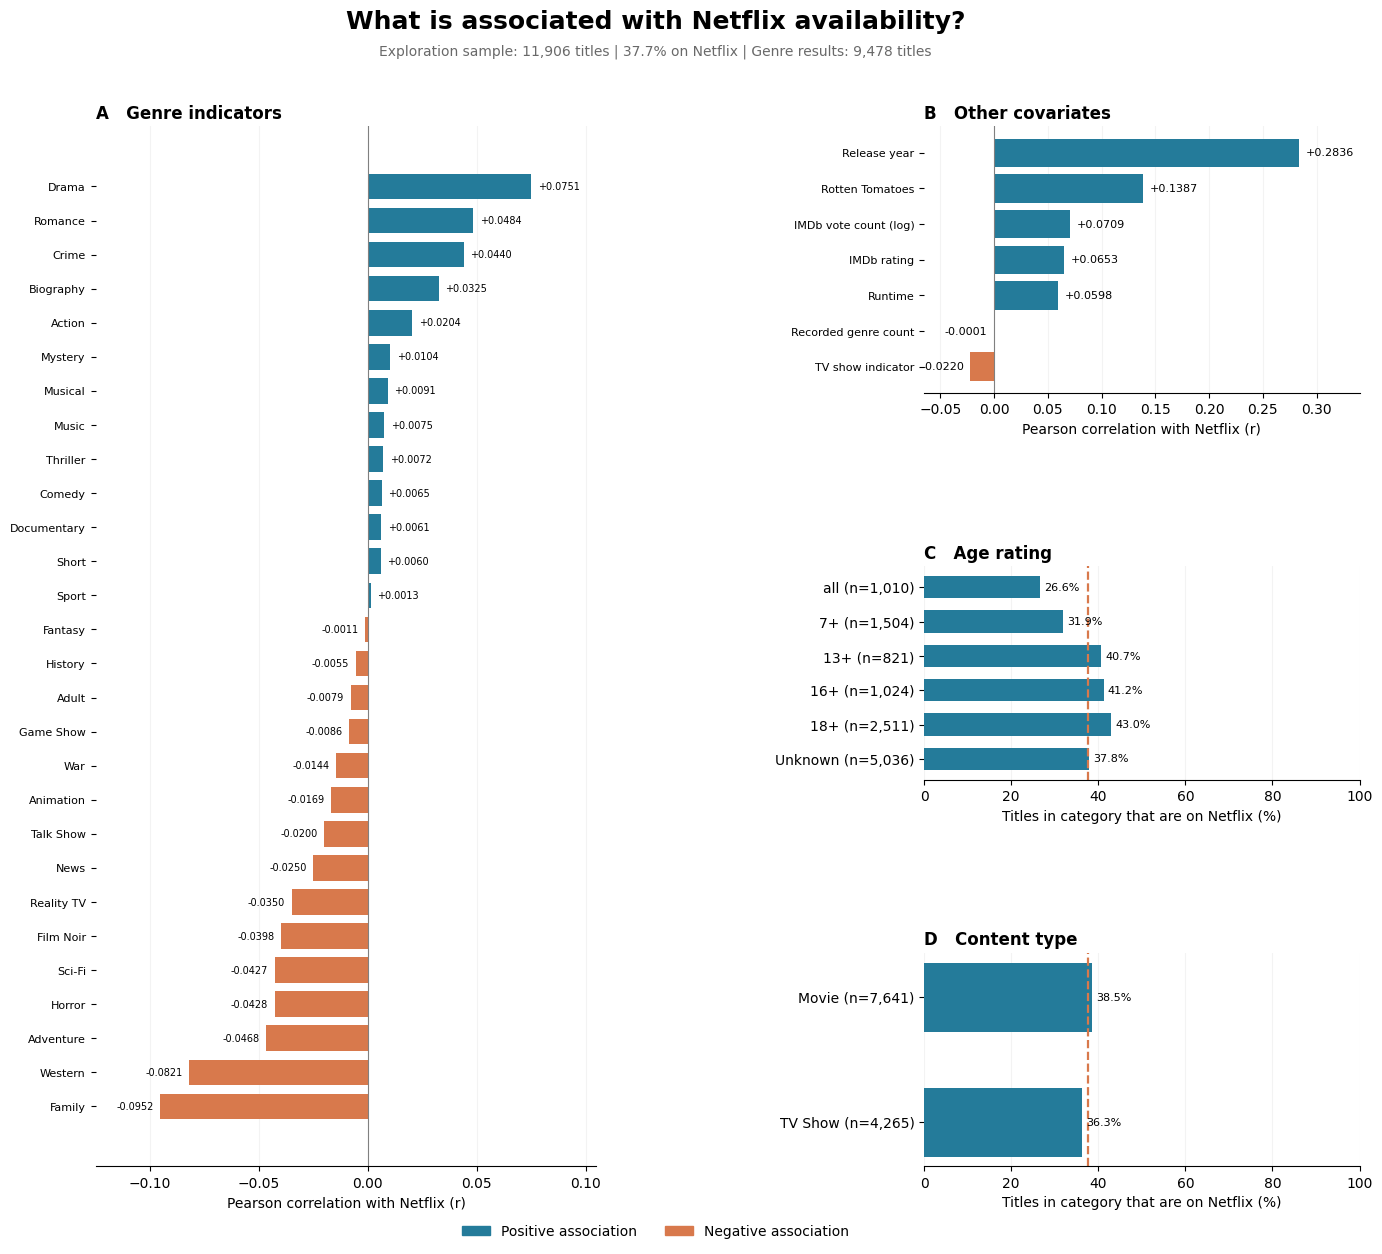

In [ ]:
import matplotlib.pyplot as plt

# Pearson correlations for genre indicators.
genre_corr = {
    "Drama": 0.0751,
    "Romance": 0.0484,
    "Crime": 0.0440,
    "Biography": 0.0325,
    "Action": 0.0204,
    "Mystery": 0.0104,
    "Musical": 0.0091,
    "Thriller": 0.0072,
    "Music": 0.0075,
    "Comedy": 0.0065,
    "Documentary": 0.0061,
    "Short": 0.0060,
    "Sport": 0.0013,
    "Fantasy": -0.0011,
    "History": -0.0055,
    "Adult": -0.0079,
    "Game Show": -0.0086,
    "War": -0.0144,
    "Animation": -0.0169,
    "Talk Show": -0.0200,
    "News": -0.0250,
    "Reality TV": -0.0350,
    "Film Noir": -0.0398,
    "Sci-Fi": -0.0427,
    "Horror": -0.0428,
    "Adventure": -0.0468,
    "Western": -0.0821,
    "Family": -0.0952
}

# Correlations for numerical and other variables.
other_corr = {
    "Release year": 0.2836,
    "Rotten Tomatoes": 0.1387,
    "IMDb rating": 0.0653,
    "Runtime": 0.0598,
    "IMDb vote count (log)": 0.0709,
    "Recorded genre count": -0.0001,
    "TV show indicator": -0.0220
}

# Netflix availability by age rating.
age_rates = {
    "all": 0.266,
    "7+": 0.319,
    "13+": 0.407,
    "16+": 0.412,
    "18+": 0.430,
    "Unknown": 0.378
}

age_counts = {
    "all": 1010,
    "7+": 1504,
    "13+": 821,
    "16+": 1024,
    "18+": 2511,
    "Unknown": 5036
}

# Netflix availability by content type.
type_rates = {
    "Movie": 0.385,
    "TV Show": 0.363
}

type_counts = {
    "Movie": 7641,
    "TV Show": 4265
}

# Overall Netflix availability.
overall_rate = 4491 / 11906

# Create one large graph on the left and three
# smaller graphs stacked vertically on the right.
fig = plt.figure(figsize=(16, 13))

gs = fig.add_gridspec(
    3, 2,
    width_ratios=[1.15, 1],
    height_ratios=[1.25, 1, 1],
    wspace=0.70,
    hspace=0.75
)

ax1 = fig.add_subplot(gs[:, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 1])
ax4 = fig.add_subplot(gs[2, 1])

# Colors indicate direction of a correlation
positive_color = "#247B9A"
negative_color = "#D8794C"

# PANEL A: GENRE CORRELATIONS
# Sort genres from lowest to highest correlation.
genres = sorted(genre_corr, key=genre_corr.get)
values = [genre_corr[g] for g in genres]

colors = [
    positive_color if value >= 0 else negative_color
    for value in values
]

ax1.barh(genres, values, color=colors, height=0.75)

# Add a vertical reference line at zero.
ax1.axvline(0, color="gray", linewidth=0.8)

# Display the correlation next to each bar.
for i, value in enumerate(values):
    offset = 0.003 if value >= 0 else -0.003

    ax1.text(
        value + offset,
        i,
        f"{value:+.4f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=7
    )

ax1.set_xlim(-0.125, 0.105)
ax1.set_xlabel("Pearson correlation with Netflix (r)")
ax1.set_title(
    "A   Genre indicators",
    fontsize=12,
    fontweight="bold",
    loc="left"
)
ax1.tick_params(axis="y", labelsize=8)
ax1.grid(axis="x", alpha=0.15)
ax1.set_axisbelow(True)


# PANEL B: OTHER COVARIATES
# Sort from lowest to highest correlation.
other_names = sorted(other_corr, key=other_corr.get)
other_values = [other_corr[name] for name in other_names]

colors = [
    positive_color if value >= 0 else negative_color
    for value in other_values
]

ax2.barh(other_names, other_values, color=colors)

ax2.axvline(0, color="gray", linewidth=0.8)

for i, value in enumerate(other_values):
    ax2.text(
        value + (0.006 if value >= 0 else -0.006),
        i,
        f"{value:+.4f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=8
    )

ax2.set_xlim(-0.065, 0.34)
ax2.set_xlabel("Pearson correlation with Netflix (r)")
ax2.set_title(
    "B   Other covariates",
    fontsize=12,
    fontweight="bold",
    loc="left"
)
ax2.tick_params(axis="y", labelsize=8)
ax2.grid(axis="x", alpha=0.15)
ax2.set_axisbelow(True)


# PANEL C: NETFLIX AVAILABILITY BY AGE RATING
age_labels = list(age_rates.keys())
age_values = [age_rates[a] * 100 for a in age_labels]

# Display category sizes in the y-axis labels.
age_display = [
    f"{a} (n={age_counts[a]:,})"
    for a in age_labels
]

ax3.barh(
    age_display,
    age_values,
    color=positive_color,
    height=0.65
)

# Add the overall Netflix rate as a reference line.
ax3.axvline(
    overall_rate * 100,
    color=negative_color,
    linestyle="--",
    linewidth=1.6
)

# Label each category's Netflix availability percentage.
for i, value in enumerate(age_values):
    ax3.text(
        value + 1,
        i,
        f"{value:.1f}%",
        va="center",
        fontsize=8
    )

ax3.invert_yaxis()
ax3.set_xlim(0, 100)
ax3.set_xlabel("Titles in category that are on Netflix (%)")
ax3.set_title(
    "C   Age rating",
    fontsize=12,
    fontweight="bold",
    loc="left"
)
ax3.grid(axis="x", alpha=0.15)
ax3.set_axisbelow(True)


# PANEL D: NETFLIX AVAILABILITY BY CONTENT TYPE
type_labels = list(type_rates.keys())
type_values = [type_rates[t] * 100 for t in type_labels]

type_display = [
    f"{t} (n={type_counts[t]:,})"
    for t in type_labels
]

ax4.barh(
    type_display,
    type_values,
    color=positive_color,
    height=0.55
)

# Overall Netflix availability reference line.
ax4.axvline(
    overall_rate * 100,
    color=negative_color,
    linestyle="--",
    linewidth=1.6
)

for i, value in enumerate(type_values):
    ax4.text(
        value + 1,
        i,
        f"{value:.1f}%",
        va="center",
        fontsize=8
    )

ax4.invert_yaxis()
ax4.set_xlim(0, 100)
ax4.set_xlabel("Titles in category that are on Netflix (%)")
ax4.set_title(
    "D   Content type",
    fontsize=12,
    fontweight="bold",
    loc="left"
)
ax4.grid(axis="x", alpha=0.15)
ax4.set_axisbelow(True)


# 3. FINAL FORMATTING
fig.suptitle(
    "What is associated with Netflix availability?",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.945,
    "Exploration sample: 11,906 titles | "
    "37.7% on Netflix | "
    "Genre results: 9,478 titles",
    ha="center",
    fontsize=10,
    color="dimgray"
)

# Remove unnecessary chart borders.
for ax in [ax1, ax2, ax3, ax4]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

# Add a legend explaining colors.
from matplotlib.patches import Patch

fig.legend(
    handles=[
        Patch(color=positive_color, label="Positive association"),
        Patch(color=negative_color, label="Negative association")
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
    bbox_to_anchor=(0.5, 0.025)
)

# Reserve space for the main title and legend.
fig.subplots_adjust(
    top=0.89,
    bottom=0.09,
    left=0.15,
    right=0.94
)

plt.show()

# Save a high-resolution image for the report.
fig.savefig(
    "netflix_availability_analysis.png",
    dpi=300,
    bbox_inches="tight"
)


In [ ]:
from google.colab import files

# Save the graph as a high-resolution PNG.
fig.savefig(
    "netflix_availability_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

#files.download("netflix_availability_analysis.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>